# Airline Satisfaction
### Baseline

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, RocCurveDisplay

In [3]:
SEED = 42
TARGET = "satisfaction"

DATA_DIR = Path("../data")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Dataset loading

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

df = train.copy()

print(f"Train: {train.shape[0]:,} rows | {train.shape[1]} columns")
print(f"Test:  {test.shape[0]:,} rows | {test.shape[1]} columns")
train.head()

Train: 699,635 rows | 23 columns
Test:  299,844 rows | 22 columns


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


## 2. Data preparation

### 2.1 Primary analysis

In [5]:
pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "unique": train.nunique(),
    "missing_train": train.isna().sum(),
    "missing_train_%": train.isna().mean().mul(100).round(2),
    "missing_test": test.isna().sum().reindex(train.columns),
})

,dtype,unique,missing_train,missing_train_%,missing_test
id,int64,699635,0,0.00,0.0
Age,int64,75,0,0.00,0.0
Flight Distance,int64,3474,0,0.00,0.0
Inflight wifi service,int64,6,0,0.00,0.0
Departure/Arrival time convenient,int64,6,0,0.00,0.0
Ease of Online booking,int64,6,0,0.00,0.0
Gate location,int64,6,0,0.00,0.0
Food and drink,int64,6,0,0.00,0.0
Online boarding,int64,6,0,0.00,0.0
Seat comfort,int64,6,0,0.00,0.0


In [6]:
cols = train.columns.drop("id", errors="ignore")

print(f"Duplicate rows: {train.duplicated(subset=cols).sum():,}")
target_counts = train[TARGET].value_counts(dropna=False)

pd.DataFrame({
    "count": target_counts,
    "share_%": (target_counts / len(train) * 100).round(2),
})

Duplicate rows: 0


,count,share_%
satisfaction,,
False,389296,55.64
True,310339,44.36


In [7]:
num_cols = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
]

cat_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
]

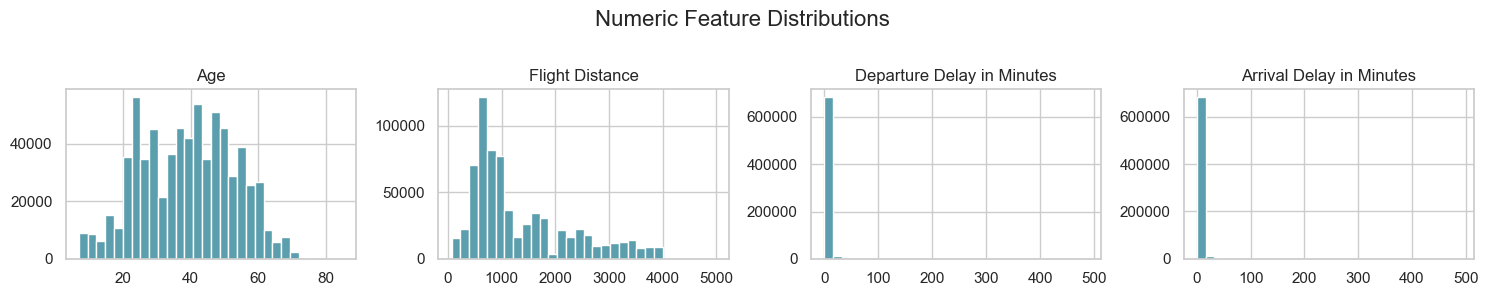

In [8]:
if num_cols:
    train[num_cols].hist(
        bins=30,
        figsize=(15, 3 * int(np.ceil(len(num_cols) / 4))),
        layout=(int(np.ceil(len(num_cols) / 4)), 4),
        color="#5B9EAD",
        edgecolor="white",
    )

    plt.suptitle("Numeric Feature Distributions", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [9]:
for col in cat_cols:
    display(
        train[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="count")
    )

,Gender,count
0,Male,351683
1,Female,347952


,Customer Type,count
0,Loyal Customer,576990
1,disloyal Customer,122645


,Type of Travel,count
0,Business travel,497441
1,Personal Travel,202194


,Class,count
0,Business,342212
1,Eco,327404
2,Eco Plus,30019


,Inflight wifi service,count
0,2,186870
1,3,184436
2,4,128136
3,1,107739
4,5,79352
5,0,13102


...

,On-board service,count
0,4,225949
1,5,173895
2,3,150812
3,2,87014
4,1,61164
5,0,801


,Leg room service,count
0,4,204124
1,5,182369
2,3,131580
3,2,126775
4,1,53094
5,0,1693


,Baggage handling,count
0,4,277622
1,5,202673
2,3,130348
3,2,58532
4,1,30460


,Checkin service,count
0,4,209592
1,3,200177
2,5,147550
3,2,74919
4,1,66468
5,0,929


,Cleanliness,count
0,4,190681
1,3,169931
2,5,162964
3,2,102596
4,1,72518
5,0,945


### 2.2 Feature engineering

In [10]:
train["Arrival Delay in Minutes"] = train["Arrival Delay in Minutes"].fillna(test["Arrival Delay in Minutes"].median())
test["Arrival Delay in Minutes"] = test["Arrival Delay in Minutes"].fillna(test["Arrival Delay in Minutes"].median())

In [11]:
str_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class",
]

train = pd.get_dummies(train, columns=str_cols, dtype=bool)
test = pd.get_dummies(test, columns=str_cols, dtype=bool)

## 3. Data training

### 3.1 Data splitting

In [16]:
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from catboost import CatBoostClassifier
from xgboost import XGBClassifier

In [17]:
X = train.drop(columns=["id", TARGET]).astype("float32")
y = train[TARGET].astype(int)

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=SEED,
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED,
)

print("Train:", X_train.shape)
print("Validation:", X_valid.shape)

Train: (559708, 26)
Validation: (139927, 26)


### 3.2 Modeling

In [18]:
cat_base = CatBoostClassifier(
    loss_function="Logloss",
    random_seed=SEED,
    thread_count=4,
    verbose=False,
    allow_writing_files=False,
)

param_dist = {
    "iterations": [600, 1000, 1500],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.08],
    "l2_leaf_reg": [3, 5, 10, 20],
    "random_strength": [0.2, 1.0, 2.0],
}

search = RandomizedSearchCV(
    estimator=cat_base,
    param_distributions=param_dist,
    n_iter=8,
    scoring="roc_auc",
    cv=cv,
    refit=True,
    random_state=SEED,
    n_jobs=1,
    verbose=2,
    return_train_score=False,
)

In [19]:
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best CV AUC: {search.best_score_:.5f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END depth=6, iterations=600, l2_leaf_reg=10, learning_rate=0.08, random_strength=0.2; total time=  10.4s
[CV] END depth=6, iterations=600, l2_leaf_reg=10, learning_rate=0.08, random_strength=0.2; total time=  10.6s
[CV] END depth=6, iterations=600, l2_leaf_reg=10, learning_rate=0.08, random_strength=0.2; total time=  10.7s
[CV] END depth=6, iterations=600, l2_leaf_reg=3, learning_rate=0.03, random_strength=0.2; total time=  10.6s
[CV] END depth=6, iterations=600, l2_leaf_reg=3, learning_rate=0.03, random_strength=0.2; total time=  10.9s
[CV] END depth=6, iterations=600, l2_leaf_reg=3, learning_rate=0.03, random_strength=0.2; total time=  10.8s
[CV] END depth=6, iterations=600, l2_leaf_reg=20, learning_rate=0.03, random_strength=2.0; total time=  10.9s
[CV] END depth=6, iterations=600, l2_leaf_reg=20, learning_rate=0.03, random_strength=2.0; total time=  11.0s
[CV] END depth=6, iterations=600, l2_leaf_reg=20, learning_rate

In [20]:
search_results = pd.DataFrame(search.cv_results_)

display(
    search_results[
        ["rank_test_score", "mean_test_score", "std_test_score", "params"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

,rank_test_score,mean_test_score,std_test_score,params
0,1,0.958617,0.000197,"{'random_strength': 1.0, 'learning_rate': 0.08..."
1,2,0.958437,0.000226,"{'random_strength': 0.2, 'learning_rate': 0.05..."
2,3,0.958300,0.000220,"{'random_strength': 0.2, 'learning_rate': 0.03..."
3,4,0.958274,0.000204,"{'random_strength': 0.2, 'learning_rate': 0.08..."
4,5,0.957559,0.000261,"{'random_strength': 0.2, 'learning_rate': 0.03..."
5,6,0.957531,0.000250,"{'random_strength': 0.2, 'learning_rate': 0.03..."
6,7,0.957346,0.000241,"{'random_strength': 2.0, 'learning_rate': 0.03..."
7,8,0.955790,0.000297,"{'random_strength': 0.2, 'learning_rate': 0.03..."


In [21]:
xgb_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=SEED,
    n_jobs=4,
)

stack = StackingClassifier(
    estimators=[
        ("catboost", clone(search.best_estimator_)),
        ("xgboost", xgb_model),
    ],
    final_estimator=LogisticRegression(
        C=1.0,
        max_iter=1000,
    ),
    stack_method="predict_proba",
    passthrough=False,
    cv=cv,
    n_jobs=1,
)

In [22]:
stack.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('catboost', ...), ('xgboost', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[CatBoostClass...verbose=False), XGBClassifier...ree=None, ...)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... ver

In [24]:
final_model = clone(candidates[best_name])
final_model.fit(X, y)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('catboost', ...), ('xgboost', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[CatBoostClass...verbose=False), XGBClassifier...ree=None, ...)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... ver

### 3.3 Evaluation

In [ ]:
candidates = {
    "CatBoost tuned": search.best_estimator_,
    "Stacking": stack,
}

scores = {}

for name, estimator in candidates.items():
    pred = estimator.predict_proba(X_valid)[:, 1]
    scores[name] = roc_auc_score(y_valid, pred)

comparison = pd.DataFrame(
    scores.items(),
    columns=["Model", "Validation AUC"],
).sort_values("Validation AUC", ascending=False)

display(comparison)

best_name = comparison.iloc[0]["Model"]
print("Selected:", best_name)

,Model,Validation AUC
1,Stacking,0.957721
0,CatBoost tuned,0.957583


Selected: Stacking


In [77]:
train_pred = cat_model.predict_proba(X_train)[:, 1]
valid_pred = cat_model.predict_proba(X_valid)[:, 1]

print(f"Train ROC-AUC:      {roc_auc_score(y_train, train_pred):.5f}")
print(f"Validation ROC-AUC: {roc_auc_score(y_valid, valid_pred):.5f}")

Train ROC-AUC:      0.96312
Validation ROC-AUC: 0.95824


## 4. Inference

In [26]:
SUBMISSION_DIR = DATA_DIR.parent / "submissions"
X_test = test[X.columns].astype("float32")

test_pred = final_model.predict_proba(X_test)[:, 1]

predictions = pd.Series(
    test_pred,
    index=test["id"],
)

submission = sample_submission.copy()
submission[TARGET] = submission["id"].map(predictions)

assert submission[TARGET].notna().all()
assert submission[TARGET].between(0, 1).all()

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

submission.to_csv(
    SUBMISSION_DIR / "tuned_ensemble.csv",
    index=False,
)

display(submission.head())

,id,satisfaction
0,699635,0.161691
1,699636,0.921015
2,699637,0.934478
3,699638,0.052726
4,699639,0.053663
